C:\Users\pedro\AppData\Local\Temp\ipykernel_20788\3125925367.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_brazil.index = pd.to_datetime(df_brazil.index)


Treinando modelo dinâmico com 10 pontos de variação de transmissão...
Isso pode demorar um pouco (estamos ajustando 12 parâmetros ao mesmo tempo)...

SUCESSO!
Gamma (Recuperação): 0.2008
Xi (Perda Imunidade): 0.00278


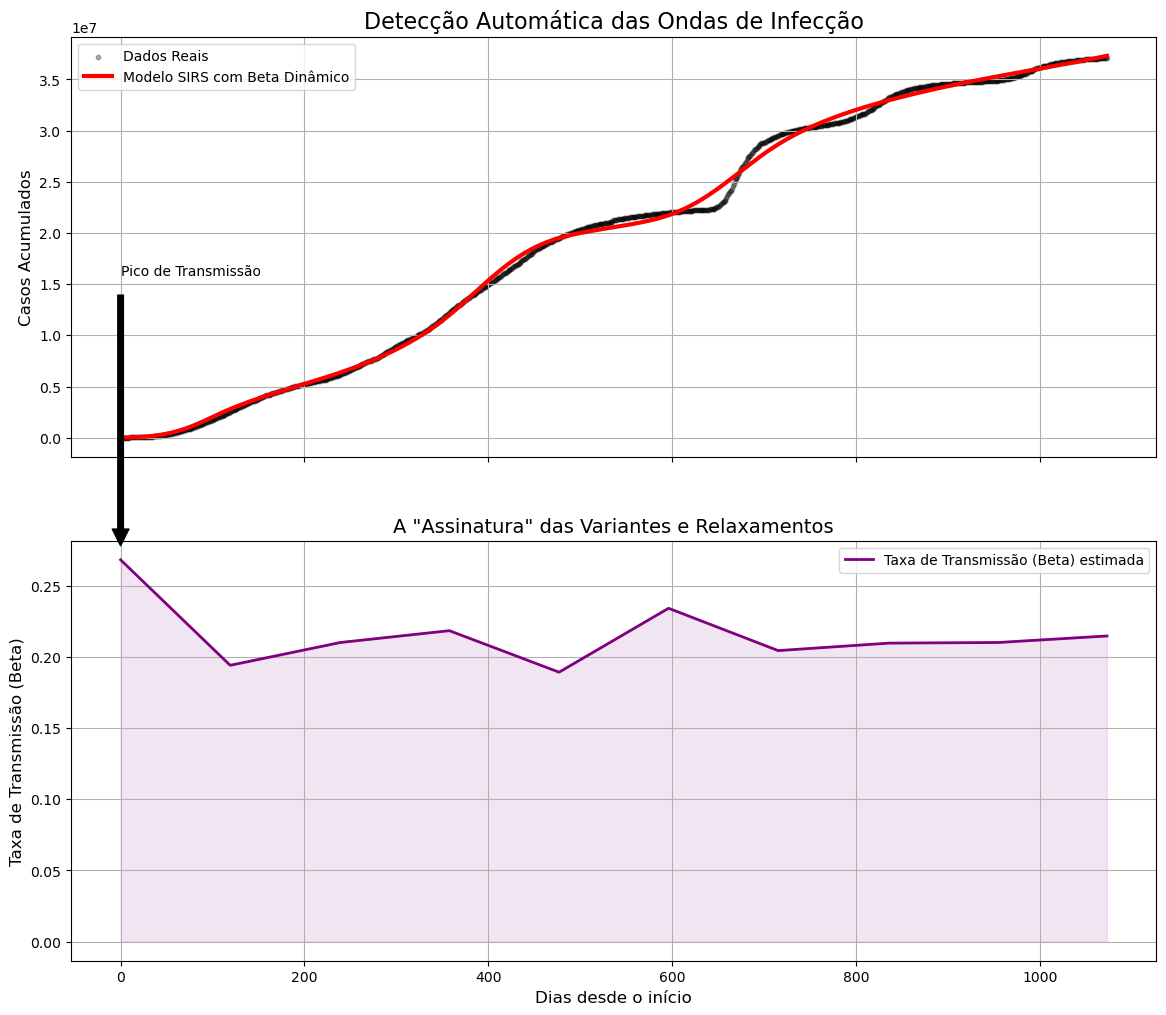

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import odeint
from scipy.optimize import curve_fit

# 1. Preparação dos Dados (Mesma de antes)
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
df_brazil = pd.read_csv(url)
df_brazil = df_brazil[df_brazil['Country/Region'] == 'Brazil'].drop(columns=['Province/State', 'Lat', 'Long', 'Country/Region']).T
df_brazil.columns = ['Confirmados']
df_brazil.index = pd.to_datetime(df_brazil.index)
df_brazil = df_brazil[df_brazil['Confirmados'] > 5000] # Corte inicial

y_real = df_brazil['Confirmados'].values
x_dias = np.arange(len(y_real))
N = 214000000

# ---------------------------------------------------------
# A GRANDE MUDANÇA: Beta Variável no Tempo
# ---------------------------------------------------------

# Vamos definir "nós" (pontos de controle) no tempo.
# O modelo vai tentar descobrir o Beta para o dia 0, dia 100, dia 200...
num_pontos_controle = 10  # Quanto maior, mais "flexível" a curva (mas mais difícil de calcular)
x_nodos = np.linspace(0, max(x_dias), num_pontos_controle)

def time_dependent_beta(t, betas_array):
    """
    Esta função recebe o tempo atual 't' e uma lista de betas descobertos.
    Ela interpola (liga os pontos) para descobrir o beta exato naquele dia.
    """
    return np.interp(t, x_nodos, betas_array)

def sirs_variable_beta_model(y, t, N, gamma, xi, *betas_array):
    S, I, R, C = y
    
    # Descobre o beta do dia atual interpolando os betas passados
    beta_hoje = time_dependent_beta(t, betas_array)
    
    dSdt = -beta_hoje * S * I / N + xi * R
    dIdt = beta_hoje * S * I / N - gamma * I
    dRdt = gamma * I - xi * R
    dCdt = beta_hoje * S * I / N
    
    return dSdt, dIdt, dRdt, dCdt

def fit_wrapper(x, gamma, xi, *betas_array):
    # Função intermediária para conectar o curve_fit ao odeint
    I0 = y_real[0]
    R0 = 0
    S0 = N - I0
    C0 = I0
    y0 = S0, I0, R0, C0
    
    # Passamos os argumentos extras (*betas_array) para a função
    ret = odeint(sirs_variable_beta_model, y0, x, args=(N, gamma, xi, *betas_array))
    return ret[:, 3] # Retorna a coluna C (Casos Acumulados)

# ---------------------------------------------------------
# Otimização Complexa
# ---------------------------------------------------------

# Chute inicial:
# Gamma e Xi constantes, mas agora precisamos de VÁRIOS Betas (um para cada nó)
p0 = [0.1, 0.001] + [0.2] * num_pontos_controle # [Gamma, Xi, Beta1, Beta2, Beta3...]

# Limites (Bounds):
# Gamma e Xi positivos. Betas entre 0 e 5.
bounds_lower = [0, 0] + [0] * num_pontos_controle
bounds_upper = [1, 0.1] + [5.0] * num_pontos_controle

print(f"Treinando modelo dinâmico com {num_pontos_controle} pontos de variação de transmissão...")
print("Isso pode demorar um pouco (estamos ajustando 12 parâmetros ao mesmo tempo)...")

try:
    popt, pcov = curve_fit(fit_wrapper, x_dias, y_real, p0=p0, bounds=(bounds_lower, bounds_upper), maxfev=10000)
    
    # Extraindo resultados
    gamma_opt = popt[0]
    xi_opt = popt[1]
    betas_opt = popt[2:] # O resto da lista são os betas
    
    print("\nSUCESSO!")
    print(f"Gamma (Recuperação): {gamma_opt:.4f}")
    print(f"Xi (Perda Imunidade): {xi_opt:.5f}")
    
    # Gerando a curva ajustada
    y_fitted = fit_wrapper(x_dias, gamma_opt, xi_opt, *betas_opt)

    # ---------------------------------------------------------
    # Visualização Dupla (Curva de Casos + Curva do Beta)
    # ---------------------------------------------------------
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=True)

    # Gráfico 1: Casos (As Ondas)
    ax1.scatter(x_dias, y_real, color='black', s=10, alpha=0.3, label='Dados Reais')
    ax1.plot(x_dias, y_fitted, color='red', linewidth=3, label='Modelo SIRS com Beta Dinâmico')
    ax1.set_ylabel('Casos Acumulados', fontsize=12)
    ax1.set_title('Detecção Automática das Ondas de Infecção', fontsize=16)
    ax1.legend()
    ax1.grid(True)

    # Gráfico 2: Como a transmissão mudou? (A "História" da Pandemia)
    # Vamos calcular o beta dia a dia para plotar
    beta_diario = [time_dependent_beta(t, betas_opt) for t in x_dias]
    
    ax2.plot(x_dias, beta_diario, color='purple', linewidth=2, label='Taxa de Transmissão (Beta) estimada')
    ax2.fill_between(x_dias, beta_diario, color='purple', alpha=0.1)
    ax2.set_ylabel('Taxa de Transmissão (Beta)', fontsize=12)
    ax2.set_xlabel('Dias desde o início', fontsize=12)
    ax2.set_title('A "Assinatura" das Variantes e Relaxamentos', fontsize=14)
    ax2.legend()
    ax2.grid(True)
    
    # Anotações automáticas nos picos de Beta
    picos_idx = np.where(beta_diario == np.max(beta_diario))[0][0]
    ax2.annotate('Pico de Transmissão', xy=(x_dias[picos_idx], beta_diario[picos_idx]), 
                 xytext=(x_dias[picos_idx], beta_diario[picos_idx]+0.2),
                 arrowprops=dict(facecolor='black', shrink=0.05))

    plt.show()

except Exception as e:
    print(f"Erro na otimização: {e}")
    print("Tente aumentar 'maxfev' ou mudar os chutes iniciais.")